# 03-ROS2工作空间、功能包与节点开发


## 1. 学习目标与资料范围

本篇对应《ROS开发入门.pdf》，从零组织一个ROS2 Python工程，理解“创建工作空间 → 创建功能包 → 编写节点 → 配置入口 → 构建 → 加载环境 → 运行”的完整链路。

课件共17页，已逐页核对PDF页面预览：1—16页为封面、目录与教学内容，第17页为品牌结束页。本篇以课件为主，图注注明页码；完整Python节点、依赖声明、验证命令与排错方法属于明确标注的工程补充。未读取视频全文或`dev_ws.zip`源码包，也未在ROS2环境中运行示例。

学习目标：

1. 分清Workspace、Package与Node。
2. 理解`src`、`build`、`install`、`log`目录的作用。
3. 使用`ament_python`创建功能包并配置`console_scripts`。
4. 理解`rclpy`节点的初始化、回调处理与关闭过程。
5. 使用`colcon build`与`ros2 run`构建和启动程序。
6. 通过SSH在Ubuntu中编辑、构建和运行工程。

前置环境沿用第02篇：Ubuntu 24.04、ROS2 Jazzy与开发工具。以下Shell命令用于Ubuntu终端，Python代码用于指定源文件；Notebook本身只包含Markdown学习单元。


## 2. 三个核心概念：工作空间、功能包、节点

课件第4页用“工业园区、生产车间、执行任务的工人”比喻ROS工程结构。

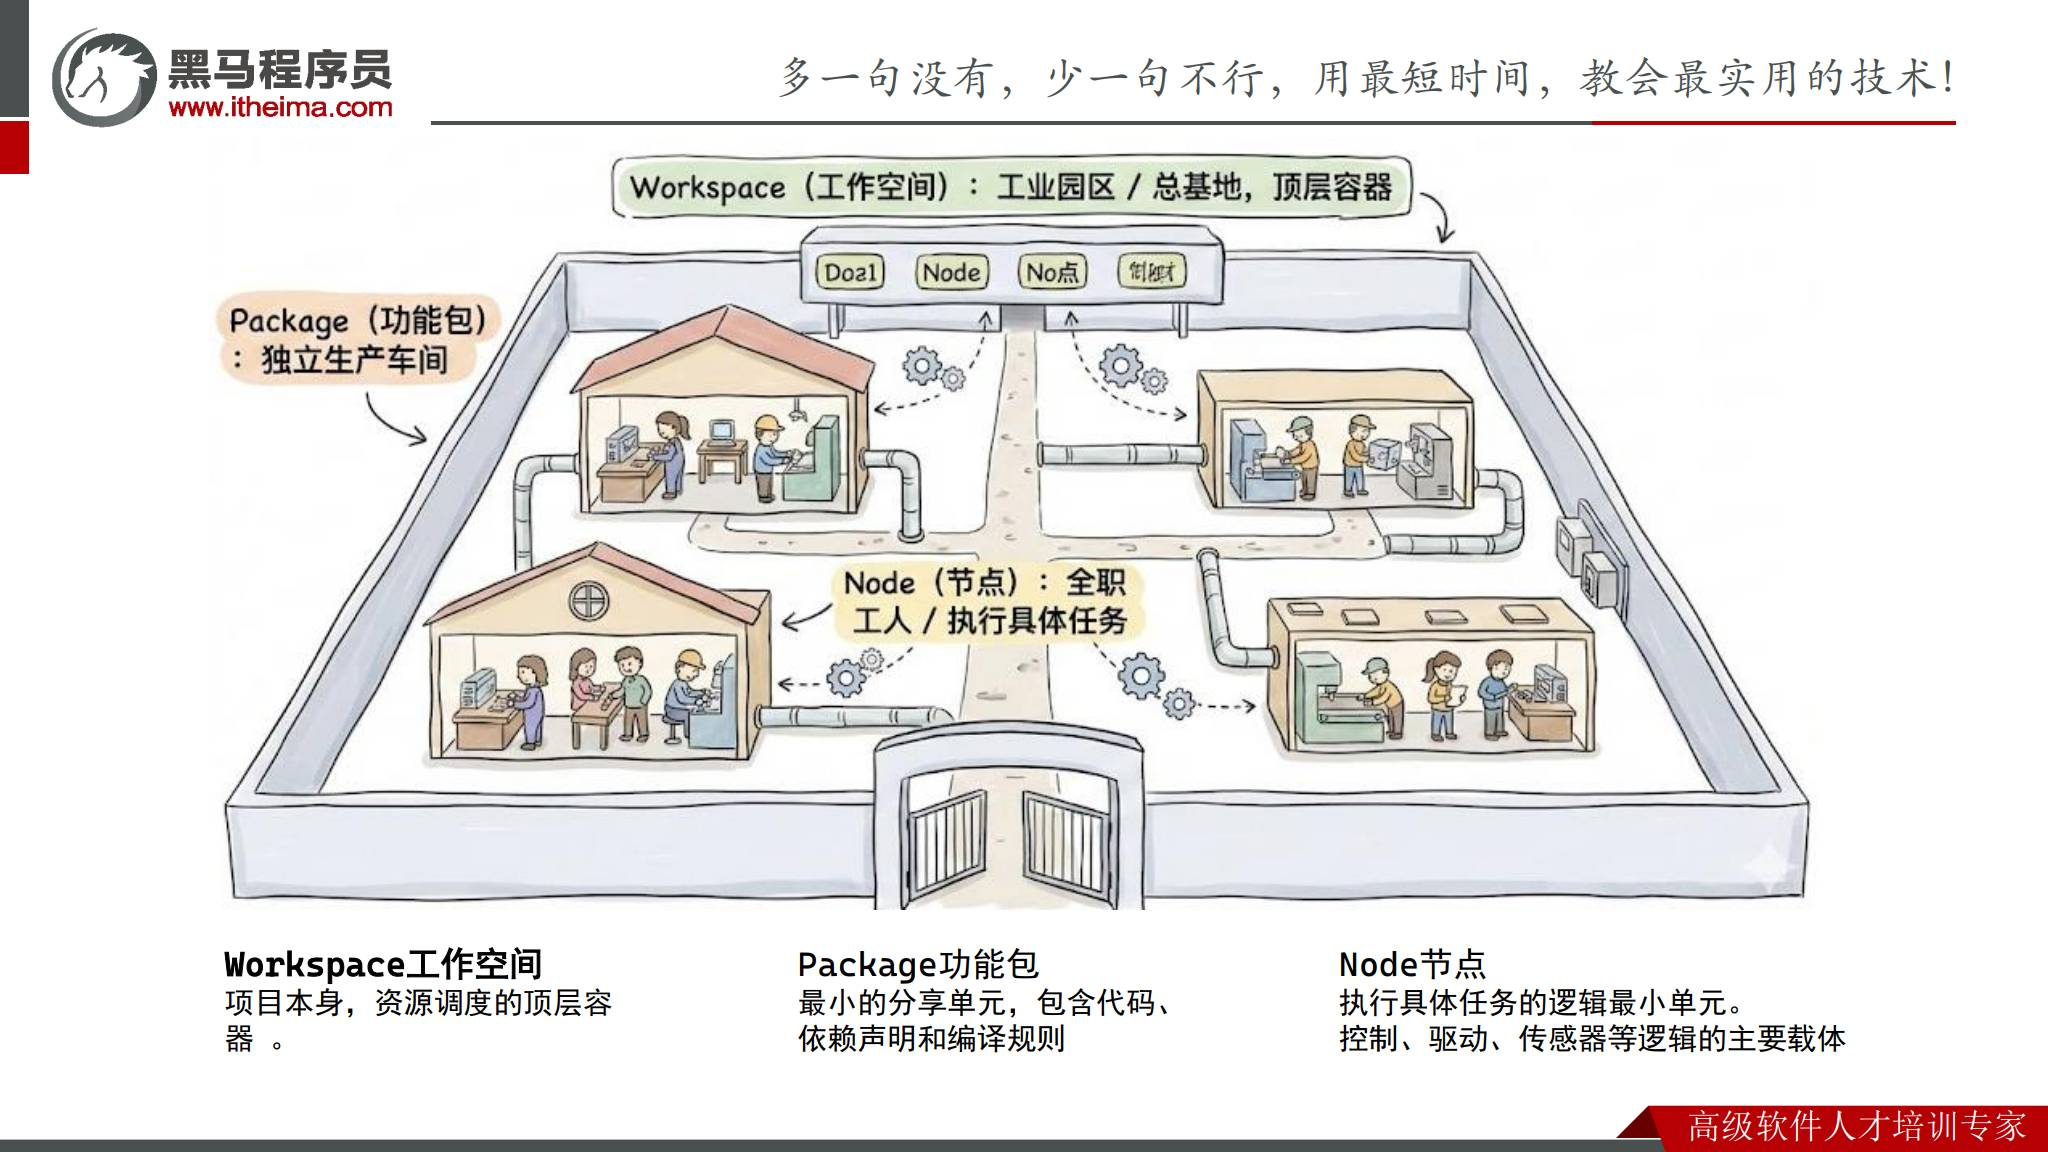

*原课件第4页：Workspace、Package与Node的层次关系。*

| 概念 | 主要含义 | 示例 |
|---|---|---|
| Workspace | 组织一组功能包及其构建结果的工程目录 | `~/dev_ws` |
| Package | 包含代码、依赖、资源与构建规则的分发单元 | `my_package` |
| Node | 运行时参与ROS图并执行任务的逻辑单元 | `hello_node` |

一个工作空间可以包含多个包，一个包可以提供多个程序与节点。节点可承担传感器采集、视觉识别或控制等任务。

**工程补充：**目录与包是工程组织概念，节点是运行时概念。创建了一个包，不表示节点已经运行；文件名、可执行入口名和节点名也不必相同。节点不是固定“一节点一进程”，只是本篇使用的简单Python程序创建一个节点。

把这三层分清，就能解释为什么`ros2 run`需要包名和可执行名，而`ros2 node list`显示的是运行中的节点名。


## 3. 开发流程：先建结构，再赋予能力

课件第5页的开发流程是：创建工作空间，在空间中创建包，在包中创建节点，再为节点增加通信与业务能力。

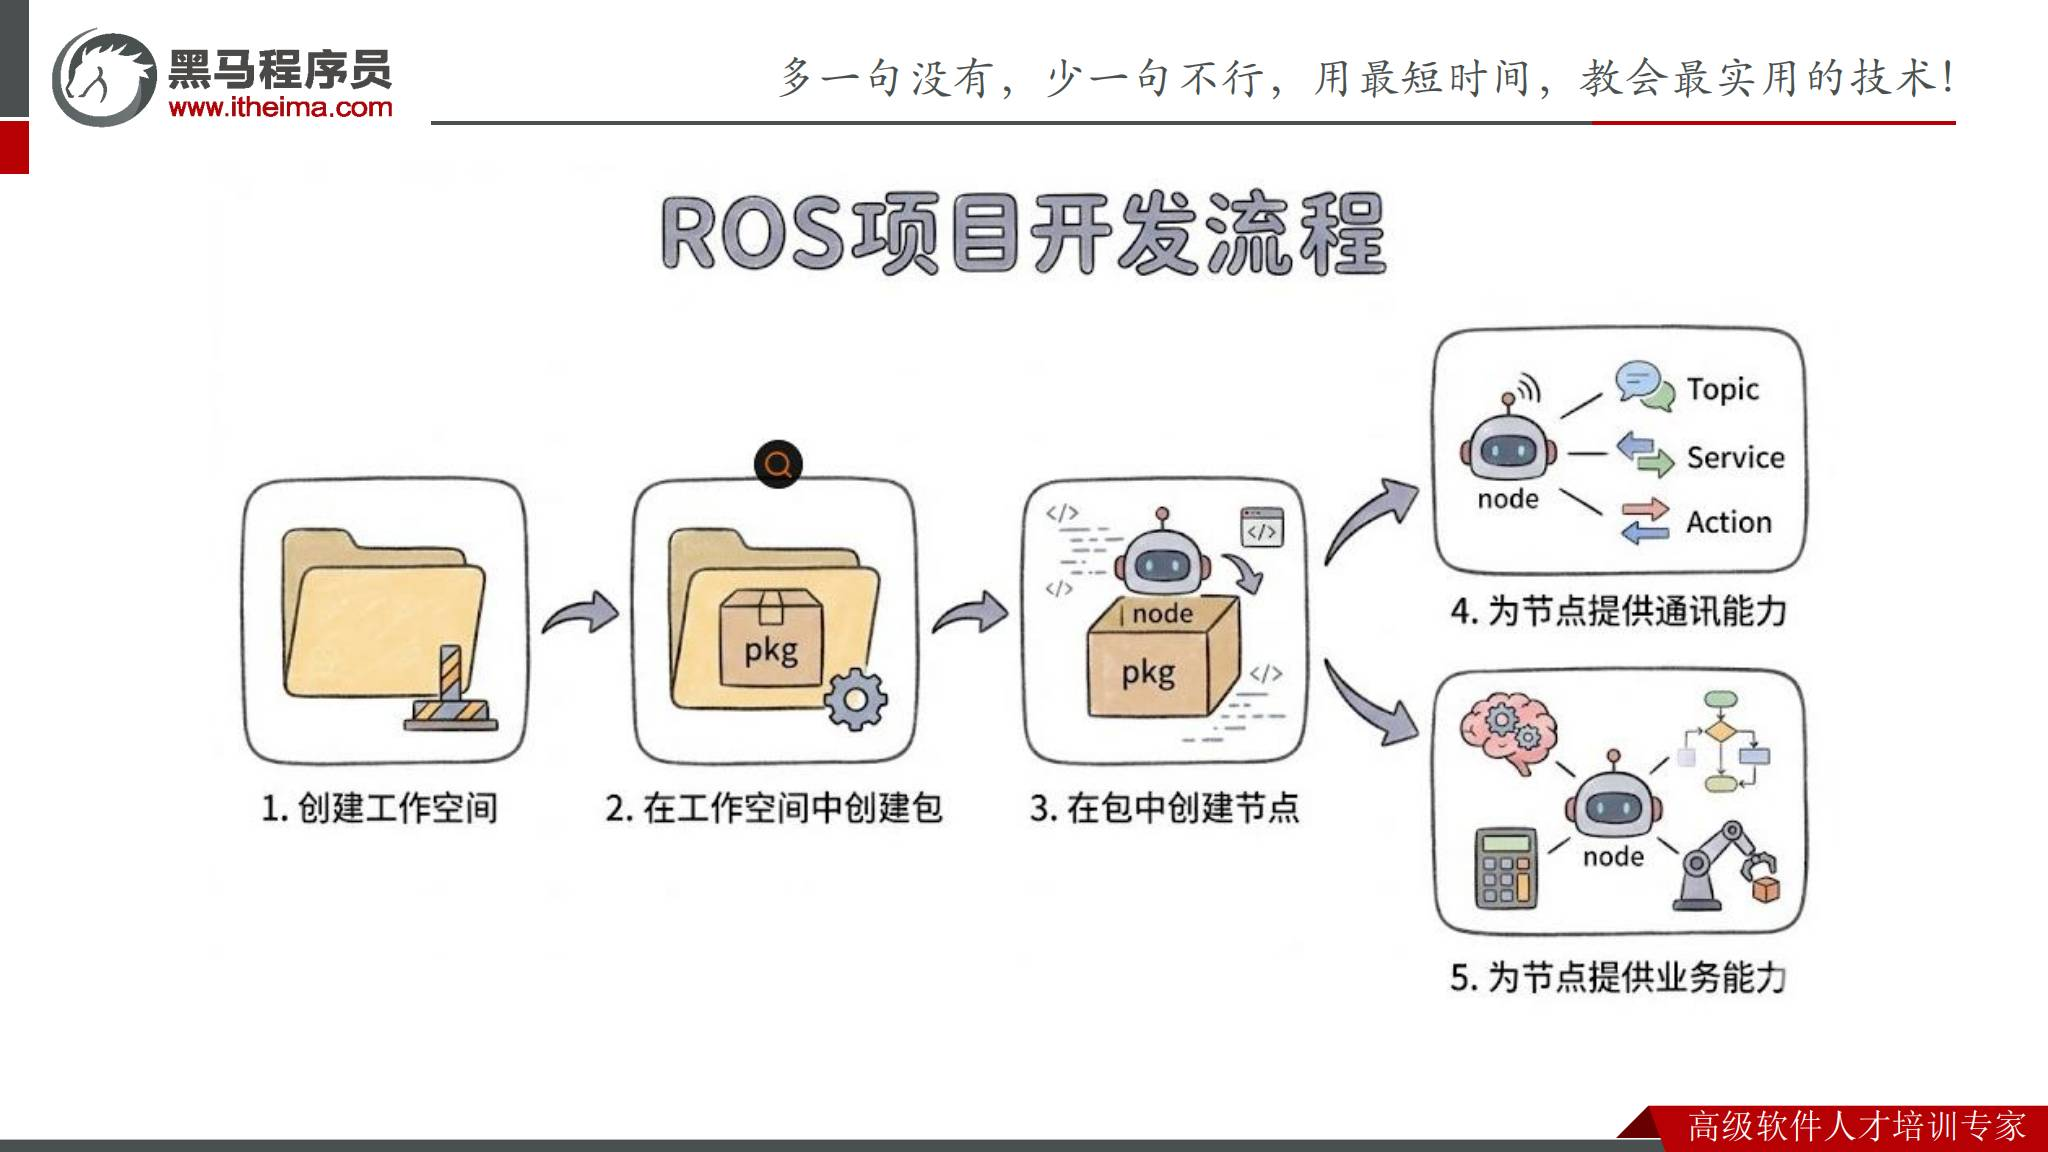

*原课件第5页：工程组织、节点通信与业务实现。*

节点能力分成两个方面：**通信能力**让模块交换数据，涉及Topic、Service和Action；**业务能力**负责具体任务，如识别、规划和控制。不能只创建空节点就认为完成机器人功能，也不能只写算法而忽略模块之间的数据约定。

本篇先把最小节点的工程链路走通，不提前实现完整机器人控制。第04篇进一步加入Topic发布与订阅。

课件第10—11页的节点创建流程补充了构建与环境加载：

```text
创建Python源文件
    ↓
配置setup.py中的入口
    ↓
在工作空间根目录colcon build
    ↓
source install/setup.bash
    ↓
ros2 run 包名 可执行入口名
```

每一步解决不同问题：源文件提供逻辑，入口让逻辑可以被启动，构建安装生成可发现的结果，环境加载让当前终端能找到结果。


## 4. 创建工作空间与认识四类目录

课件第6—7页进入工作空间创建。为了明确当前目录，完整操作整理为：

```bash
source /opt/ros/jazzy/setup.bash
mkdir -p ~/dev_ws/src
cd ~/dev_ws
colcon build
```

`mkdir -p`创建所需目录，`cd`把工作目录切到工作空间根目录，`colcon build`执行构建。第一次空工作空间没有包可编译；它不能验证业务代码，创建包后仍需重新构建。

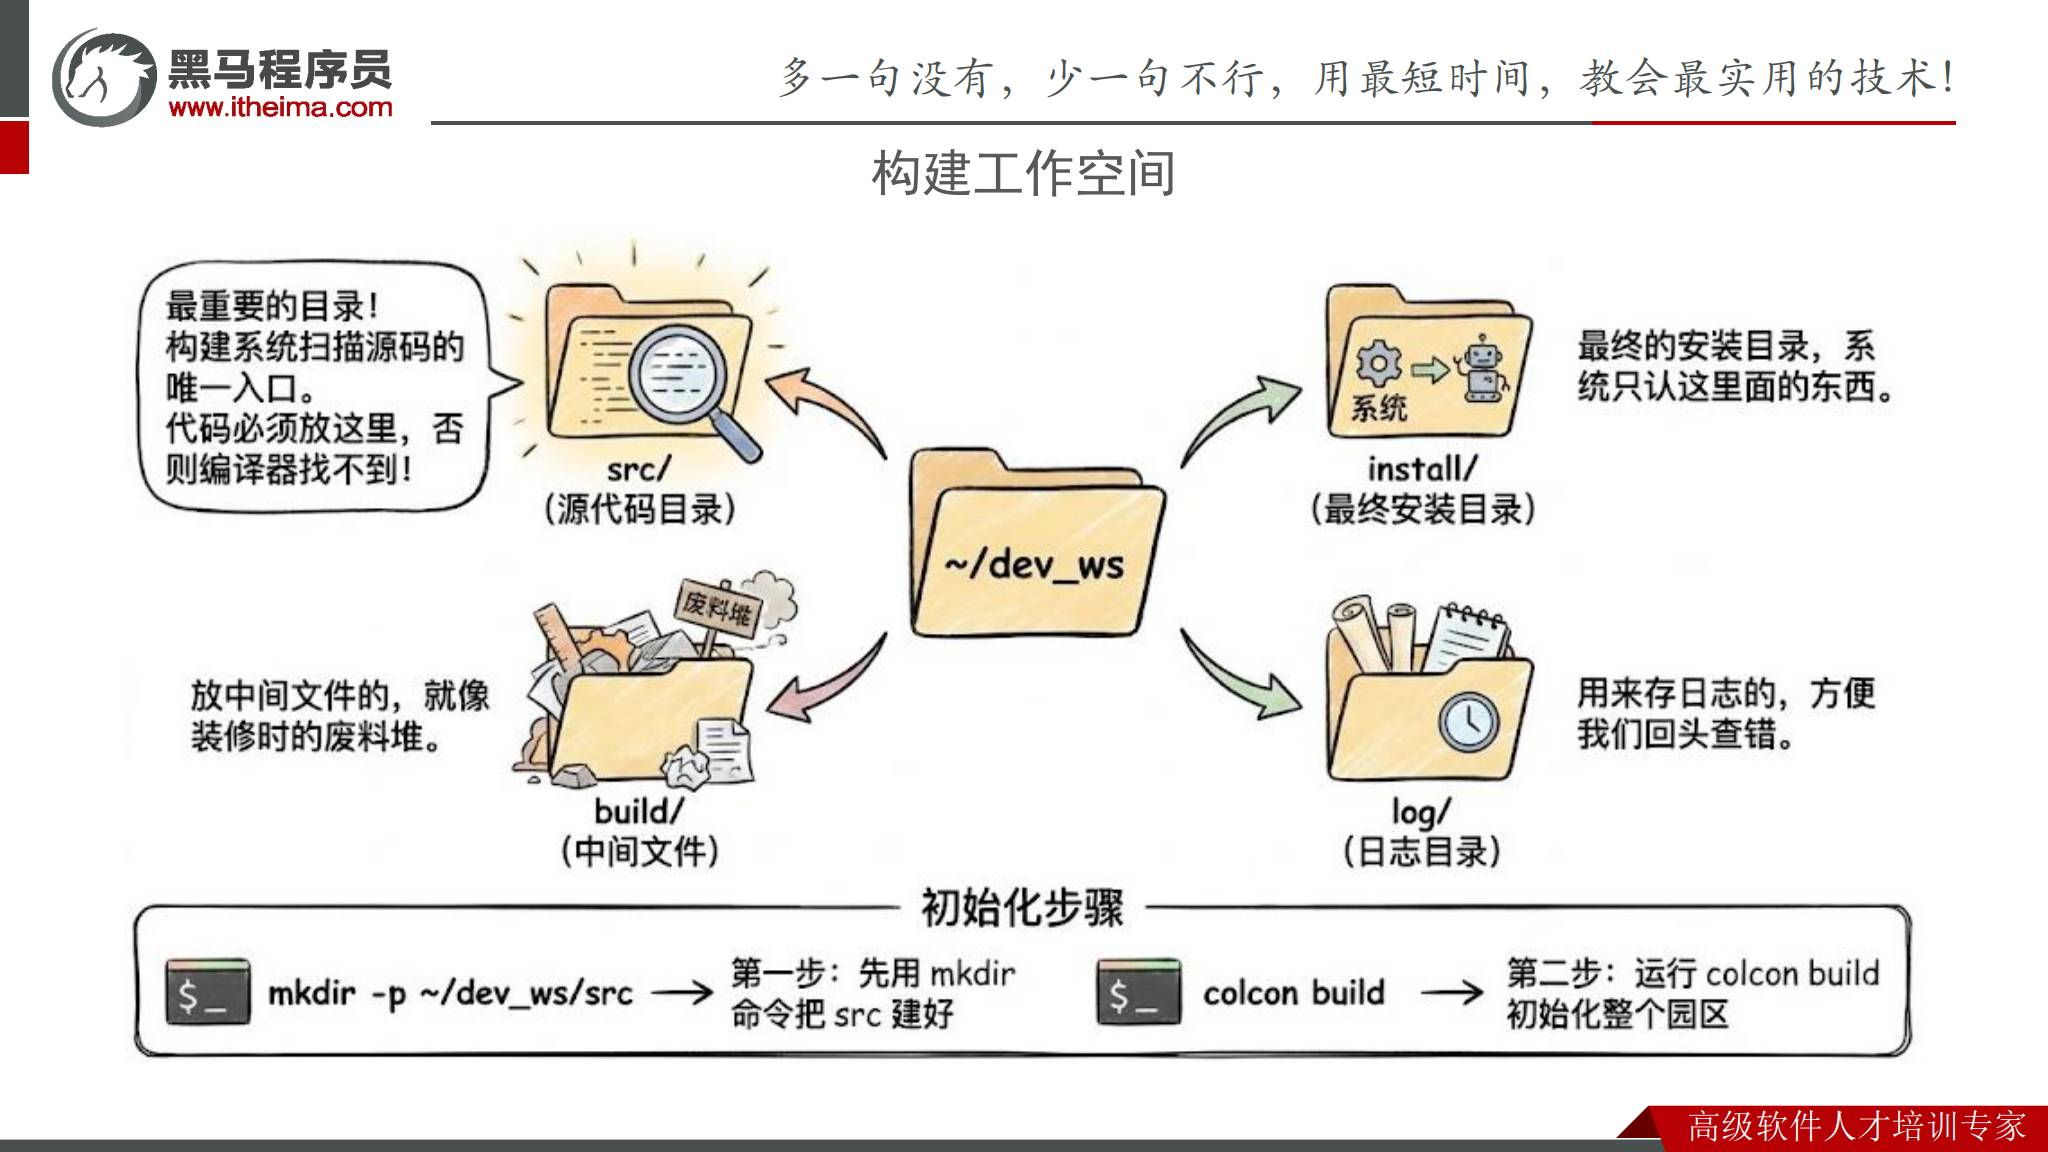

*原课件第7页：src、build、install、log及初始化步骤。*

| 目录 | 作用 | 日常操作 |
|---|---|---|
| `src/` | 放置本工作空间的功能包源码 | 在这里编写与管理项目代码 |
| `build/` | 保存构建中间产物 | 构建工具生成，不直接当作源码编辑 |
| `install/` | 保存安装结果与环境脚本 | 构建后加载这里的环境 |
| `log/` | 保存构建日志 | 构建失败时查具体错误 |

**工程补充：**课件将`src`称为源码扫描的唯一入口，这是本课程标准目录约定的简化说明。`colcon`的搜索范围可配置，并不是工具在所有情况下只认名为`src`的目录。学习阶段遵循该结构，能减少目录混乱。

同样，“系统只认install”表达的是运行环境使用安装结果。源码仍用于编辑与构建，不能因为存在`install`就把`src`当成无用目录。


## 5. 创建ament_python功能包

课件第8页使用Python包类型，示例命令为：

```bash
cd ~/dev_ws/src
ros2 pkg create --build-type ament_python --node-name my_node my_package
```

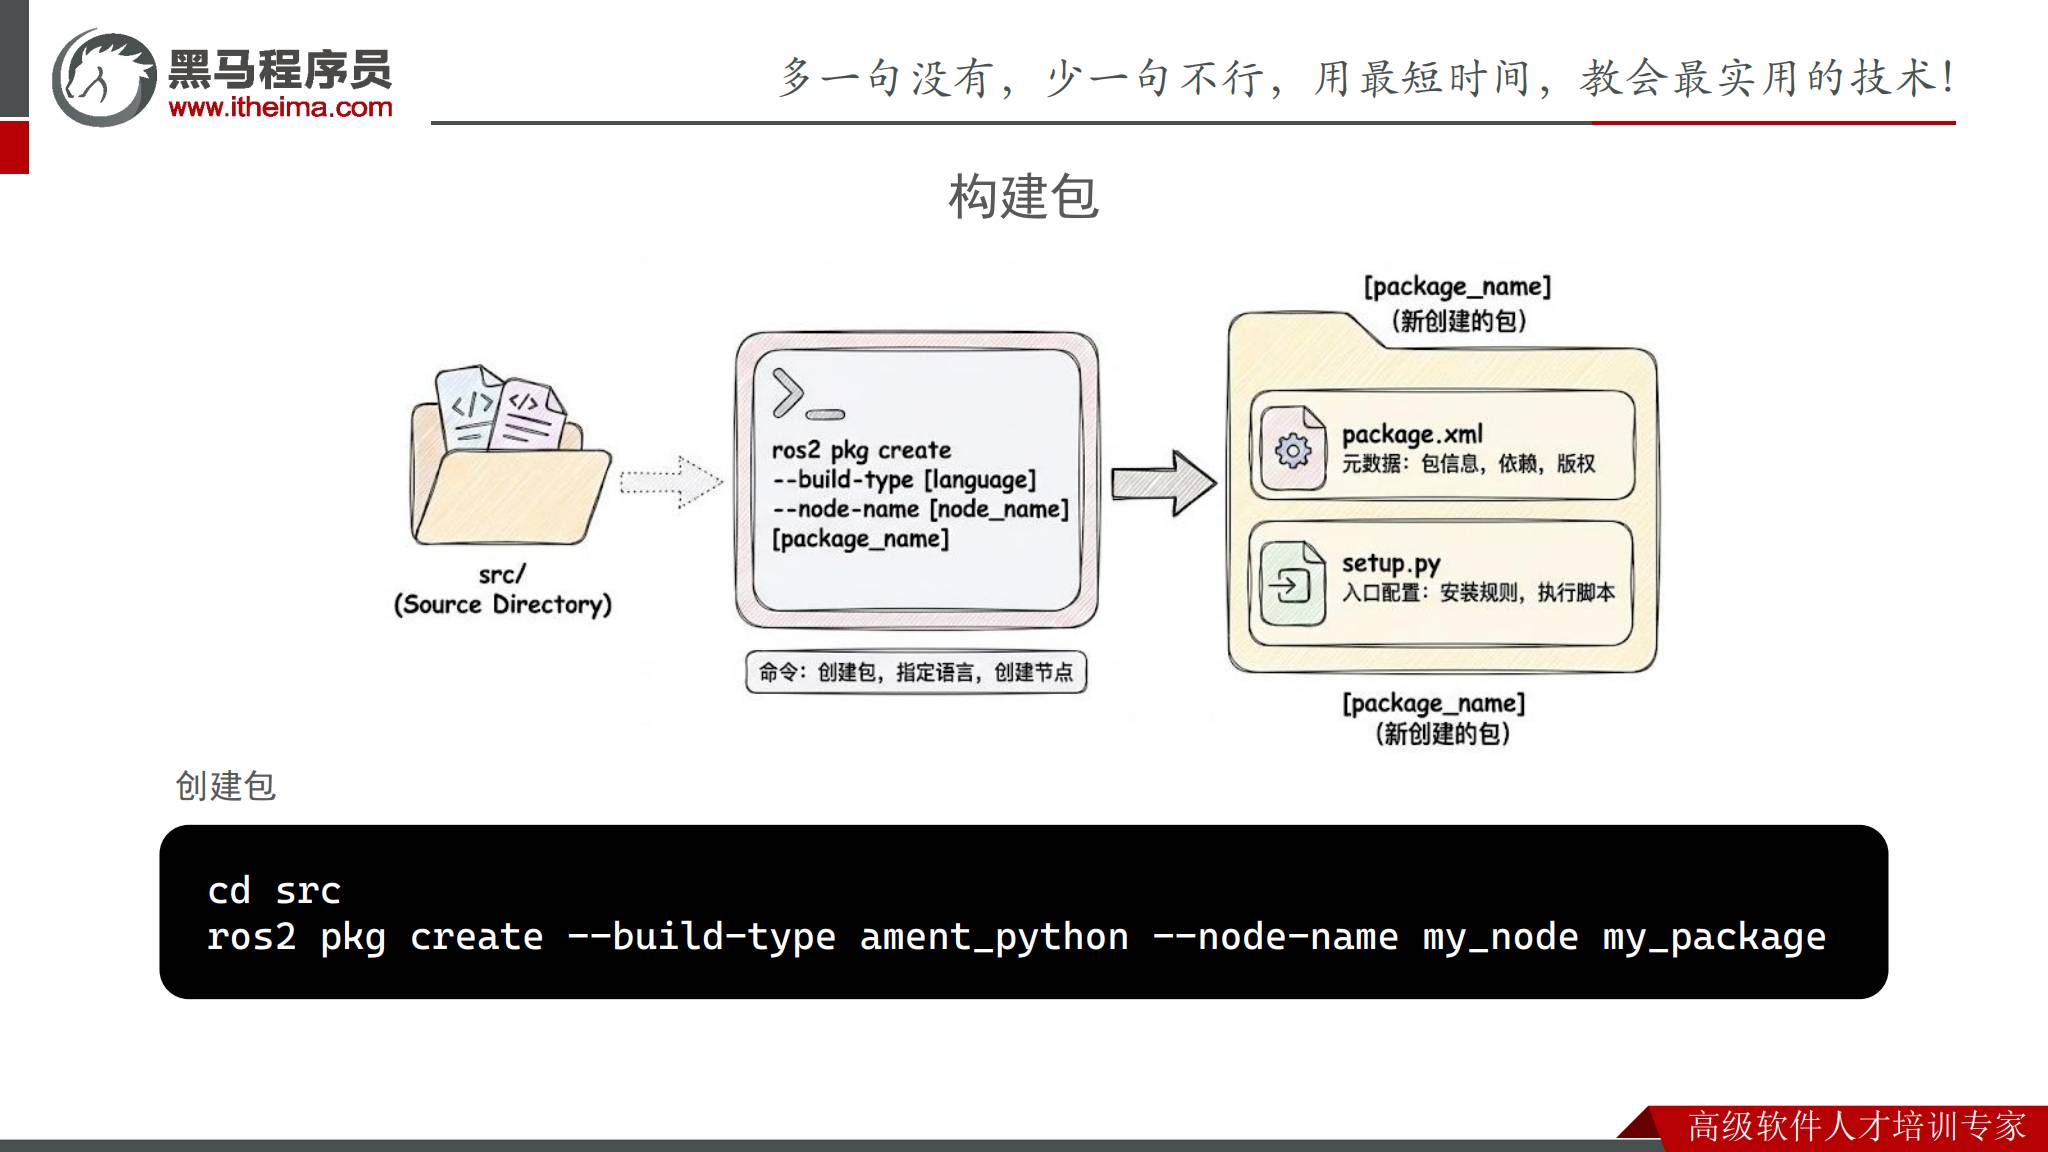

*原课件第8页：包类型、节点模板名与包名。*

| 参数 | 意义 |
|---|---|
| `ros2 pkg create` | 生成ROS包的基本结构 |
| `--build-type ament_python` | 使用Python包构建类型 |
| `--node-name my_node` | 创建名为my_node的Python程序模板与相应入口 |
| `my_package` | 功能包名称 |

**工程补充：**`--build-type`不是简单填写语言名`python`，这里的合法类型是`ament_python`。模板文件也不保证已经包含完整`rclpy`节点逻辑，仍要检查并补充实际代码。

因为后续示例要导入`rclpy`，新建空工程时可用下面这一条**替代上面的创建命令**，提前声明依赖：

```bash
ros2 pkg create --build-type ament_python --node-name my_node --dependencies rclpy my_package
```

两种创建命令选一种执行，不要在同一位置重复创建同名包。如果已按课件创建，直接补充`package.xml`中的依赖即可。

**预期目录结构（具体测试模板依工具版本而定）：**

```text
~/dev_ws/src/my_package/
├── package.xml
├── setup.py
├── setup.cfg
├── resource/
│   └── my_package
├── my_package/
│   ├── __init__.py
│   └── my_node.py
└── test/
```

外层`my_package`是ROS功能包根目录，内层同名目录是Python模块包。节点源码放在内层目录，`setup.py`放在外层目录。


## 6. 包配置文件与依赖声明

课件重点展示`package.xml`与`setup.py`。工程中还会看到`setup.cfg`、`resource`标记和Python的`__init__.py`。

| 文件或目录 | 主要职责 |
|---|---|
| `package.xml` | 包名、版本、维护者、许可证和ROS依赖声明 |
| `setup.py` | Python安装配置、资源安装与程序入口 |
| `setup.cfg` | 控制脚本安装位置等配置，让ROS按约定查找可执行程序 |
| `resource/my_package` | 包资源索引标记 |
| `my_package/__init__.py` | 标识Python模块包 |

**工程补充：**采用上一节含`--dependencies rclpy`的命令时，生成器会处理相应依赖声明；已创建的包可检查`package.xml`。至少应有对应`rclpy`的运行依赖，如：

```xml
<exec_depend>rclpy</exec_depend>
```

将这一行放到已有`<package>...</package>`内，保留原来的构建工具声明、其他依赖和`<export>`配置。生成器使用`<depend>rclpy</depend>`等合适的依赖形式时，不必再重复添加同一依赖。

`package.xml`用于描述ROS依赖，`setup.py`中的`install_requires`用于Python打包依赖，二者职责不同。不能把缺少ROS环境的问题简单解决成对系统Python执行一次`pip install`。

包能在自己的电脑上导入，不代表依赖声明已经完整。显式声明依赖有助于构建、部署和交给别人使用。


## 7. 编写Hello World节点：工程补充示例

课件第11页要求创建Python文件并配置入口，但未展示完整节点源码。下面的代码是本篇为讲清流程编写的**学习示例，不是源码附件的转录**。

将代码写入`~/dev_ws/src/my_package/my_package/my_node.py`，替换该文件中原有模板内容：

```python
import rclpy
from rclpy.node import Node


class HelloNode(Node):
    def __init__(self):
        super().__init__('hello_node')
        self.count = 0
        self.timer = self.create_timer(1.0, self.on_timer)
        self.get_logger().info('Hello World node started')

    def on_timer(self):
        self.count += 1
        self.get_logger().info(f'Hello ROS2! count={self.count}')


def main(args=None):
    rclpy.init(args=args)
    node = None
    try:
        node = HelloNode()
        rclpy.spin(node)
    except KeyboardInterrupt:
        pass
    finally:
        if node is not None:
            node.destroy_node()
        if rclpy.ok():
            rclpy.shutdown()


if __name__ == '__main__':
    main()
```

| 代码部分 | 作用 |
|---|---|
| `rclpy.init()` | 初始化ROS2 Python上下文 |
| `Node`子类 | 封装一个节点的状态与回调 |
| `super().__init__('hello_node')` | 创建运行时名称为hello_node的节点 |
| `create_timer(1.0, ...)` | 注册周期回调，示例目标周期为1秒 |
| `get_logger().info()` | 输出带节点信息的日志 |
| `rclpy.spin(node)` | 驱动执行器处理该节点的回调 |
| `destroy_node()`与`shutdown()` | 释放节点资源并关闭上下文 |

`spin`不是业务上的死循环写法，它让执行器持续处理准备好的回调。如果创建定时器后马上退出程序，回调不会持续执行。

**工程补充：**1秒是定时器设置的周期，不是硬实时保证；回调执行仍受调度与系统负载影响。本例演示节点与回调，没有创建自定义Topic，也没有控制真实硬件。


## 8. 配置console_scripts与分清各种名称

课件第11页在`setup.py`的`entry_points`中配置Python程序入口：

```python
entry_points={
    'console_scripts': [
        'my_node = my_package.my_node:main',
    ],
},
```

这段配置应位于已有`setup(...)`调用中。不要把它当成整个`setup.py`文件；生成器已经创建入口时，检查内容即可，避免重复添加。

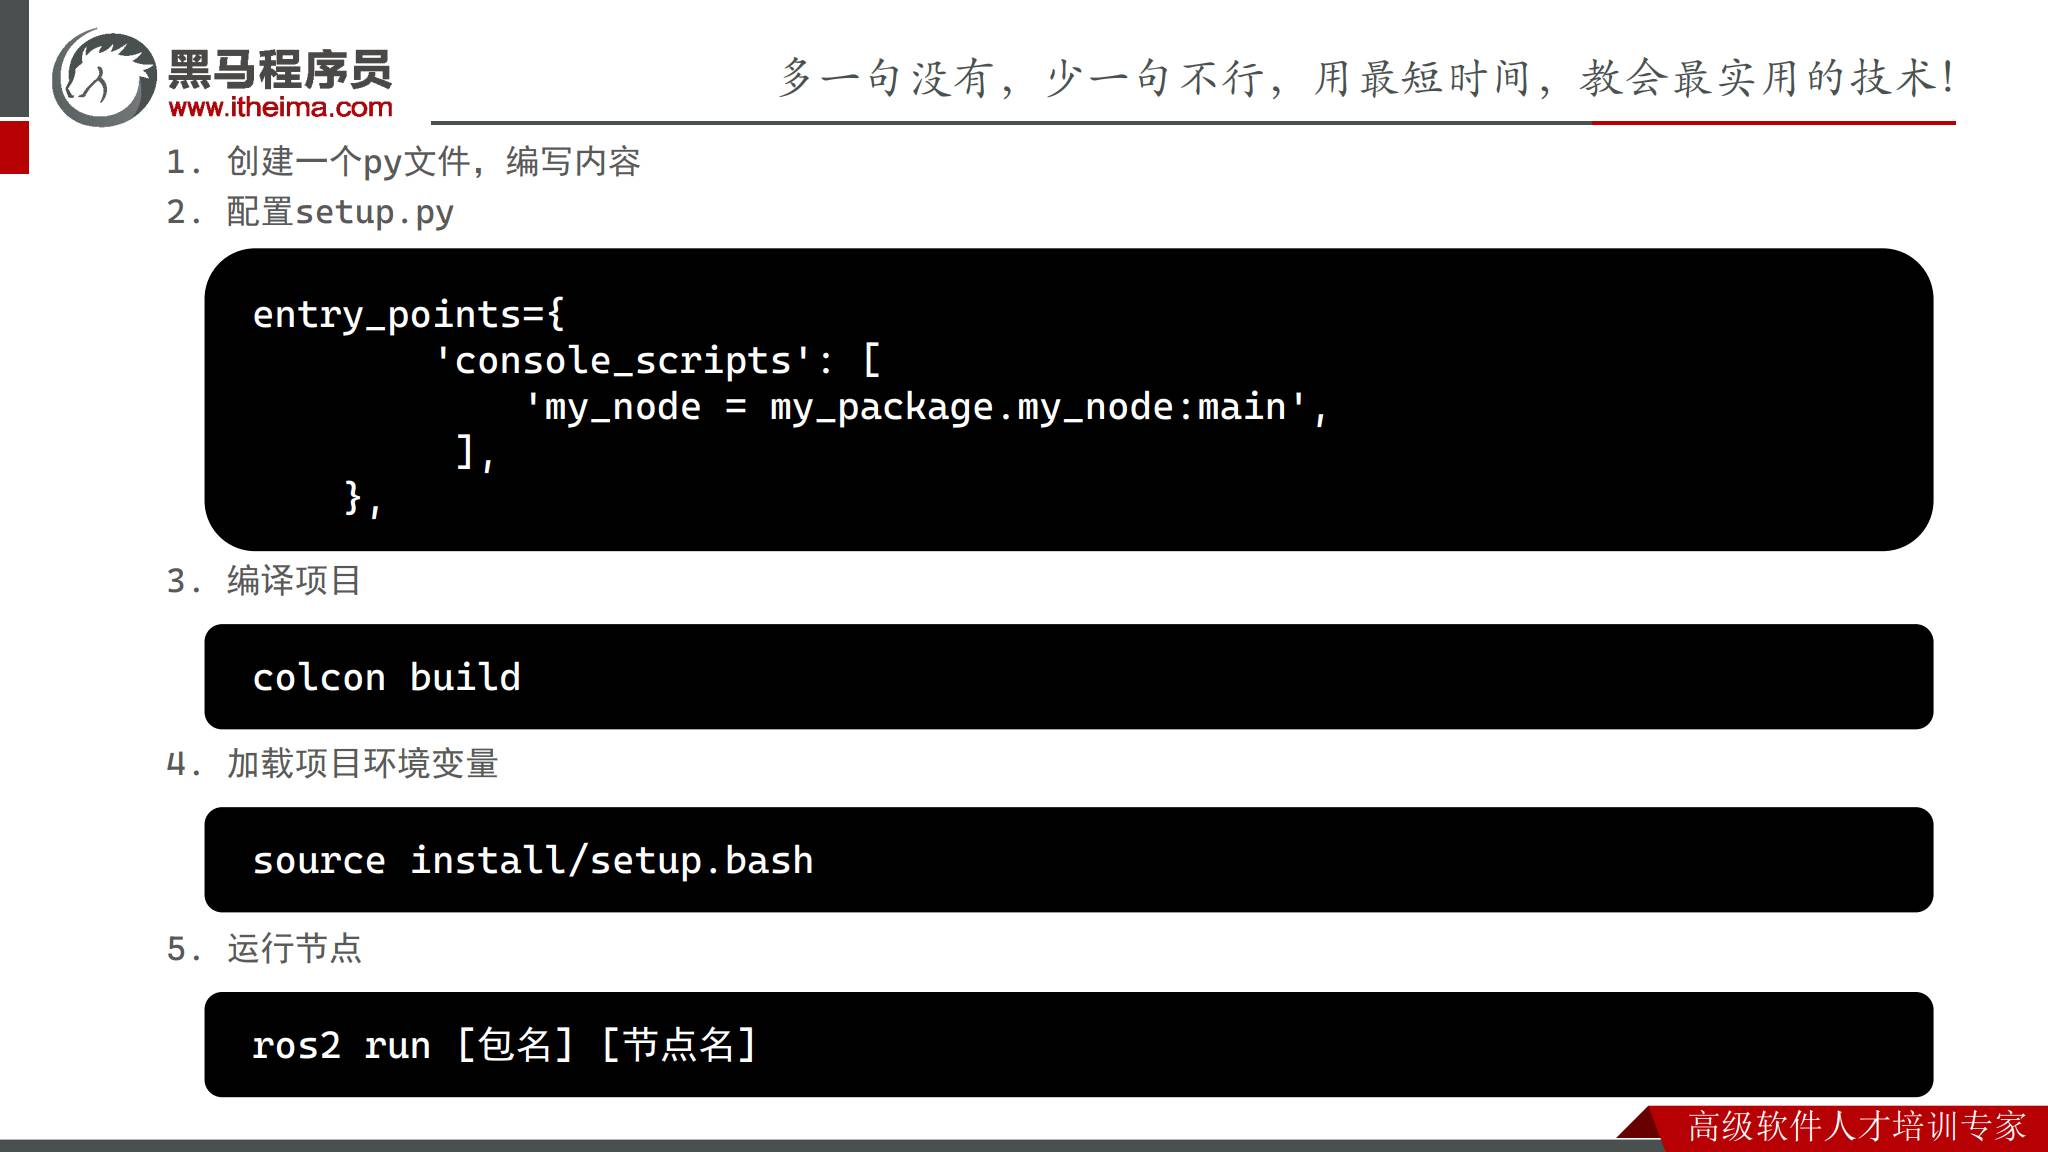

*原课件第11页：console_scripts与节点运行步骤。*

入口格式为：

```text
可执行入口名 = Python模块路径:函数名
my_node      = my_package.my_node:main
```

| 名称 | 本例值 | 使用位置 |
|---|---|---|
| ROS包名 | `my_package` | `ros2 run`的第一个参数 |
| 源文件名 | `my_node.py` | Python源文件 |
| Python模块路径 | `my_package.my_node` | setup.py入口右侧 |
| 入口函数 | `main` | 冒号后，启动时调用 |
| 可执行入口名 | `my_node` | `ros2 run`的第二个参数 |
| 运行时节点名 | `hello_node` | Node构造函数、ROS图中的名称 |

因此运行`ros2 run my_package my_node`后，`ros2 node list`中预期显示`/hello_node`，而不是必须显示`/my_node`。

入口名与节点名可以取相同值，但含义仍然不同。`ros2 run`的第二个参数一般是已安装的可执行名，不能统一理解成ROS图中的节点名。


## 9. 构建、加载环境与运行

代码和配置保存后，回到工作空间根目录构建：

```bash
cd ~/dev_ws
source /opt/ros/jazzy/setup.bash
colcon build
```

确认构建结果没有未处理的失败，再加载项目环境并运行：

```bash
source ~/dev_ws/install/setup.bash
ros2 run my_package my_node
```

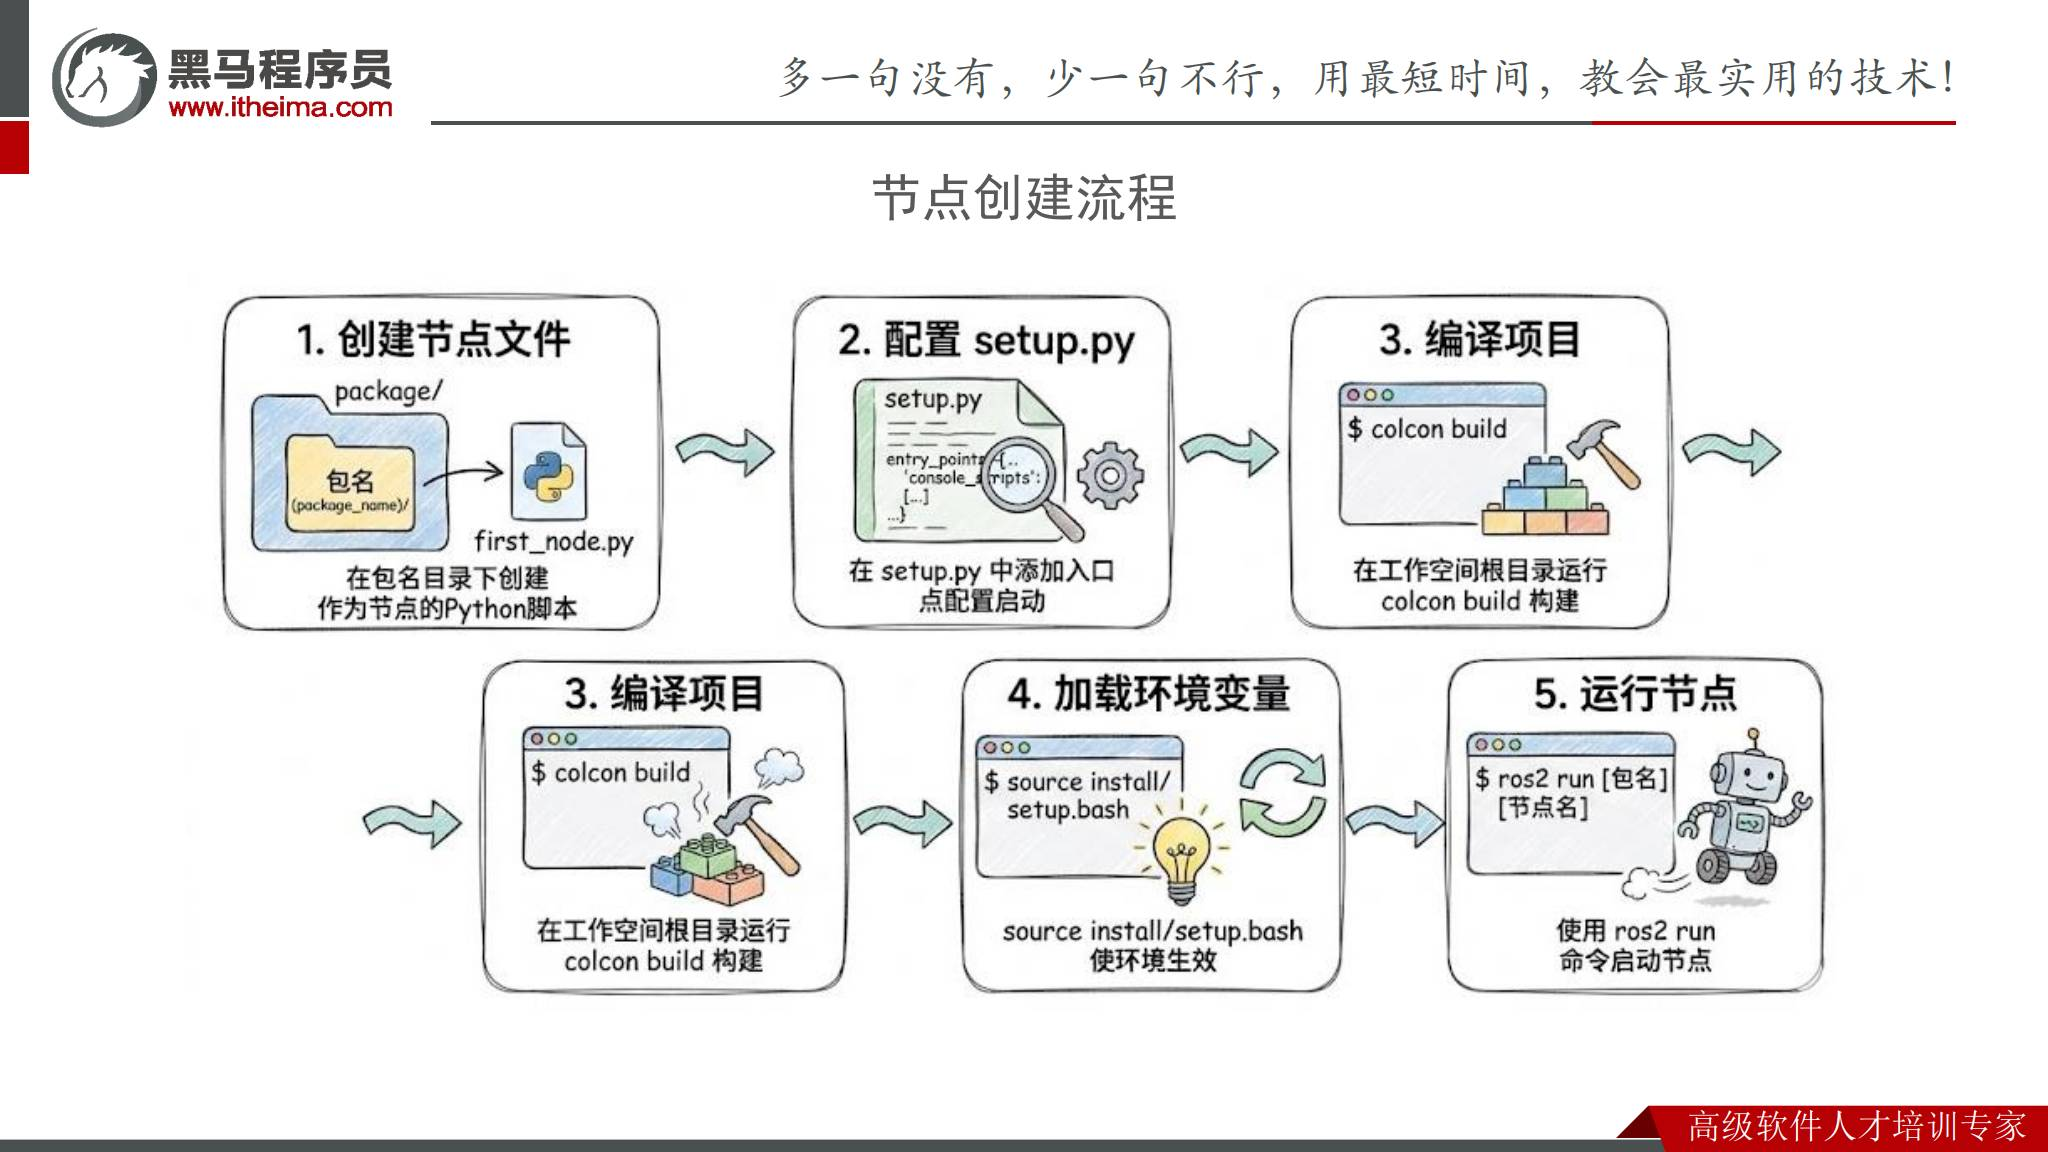

*原课件第10页：配置入口、构建、source与ros2 run。图中构建步骤重复出现，实际按流程完成一次即可。*

**两个环境层：**`/opt/ros/jazzy/setup.bash`提供系统ROS环境，`~/dev_ws/install/setup.bash`提供自己工作空间的安装环境。后者是工作空间叠加环境，不会凭空生成尚未构建成功的包。

推荐在一个干净终端中加载系统ROS并构建，再在运行终端中加载系统与工作空间环境。重新打开终端后，之前终端的`source`不会自动传过去，除非已经在启动配置中设置。

**工程补充：**`colcon build`也用于Python包的构建安装，不是只有C++才需要。Python源码修改后，普通构建模式下需要更新安装结果；新增入口或调整配置后同样要重新构建。

开发时可评估`colcon build --symlink-install`，减少部分Python源码更新的复制步骤。但它不能免除所有构建操作，特别是修改打包配置、入口或安装文件时。

运行后通常可见启动日志，并按周期出现`Hello ROS2! count=...`。这属于示例的预期行为，不是本篇在ROS2运行环境中的实测记录。


## 10. 检查包、可执行入口与运行节点

以下为工程补充，用于区分“源码存在”“包可发现”“入口可用”和“节点已运行”。

在已经加载项目环境的终端中：

```bash
ros2 pkg prefix my_package
ros2 pkg executables my_package
```

第一条显示当前环境选择的包安装位置，第二条列出该包注册的可执行程序。预期能找到`my_package`以及`my_node`入口。

启动节点后，在另一个终端中加载同一环境并检查：

```bash
source /opt/ros/jazzy/setup.bash
source ~/dev_ws/install/setup.bash
ros2 node list
ros2 node info /hello_node
```

`node list`预期出现`/hello_node`；`node info`查看该节点的通信接口。本例只有日志与定时回调，没有自定义业务Topic。ROS默认日志和参数等接口可能出现在节点信息中，不代表已经实现后续课程的发布订阅业务。

停止程序时，在启动它的终端按`Ctrl+C`。然后观察节点是否退出。若CLI显示与实际状态不一致，再检查具体环境、域设置或CLI发现状态，不只靠一条输出判断整个系统。

**验证层次：**构建成功 → 包和入口可发现 → 程序可启动 → 节点存在 → 回调日志持续输出。这些检查逐层缩小问题范围。


## 11. IDE远程开发：Windows编辑，Ubuntu执行

课件第12—16页介绍IDE开发环境，采用Trae及其远程SSH配置。第13页用“理解需求、调用工具、完成开发任务”介绍AI辅助开发能力；这些是工具用途说明，不表示生成代码可以跳过检查和验证。

操作路线：打开Trae远程配置面板 → 新增远程连接 → 输入SSH连接信息 → 输入Ubuntu登录密码 → 连接后打开Ubuntu工程目录。

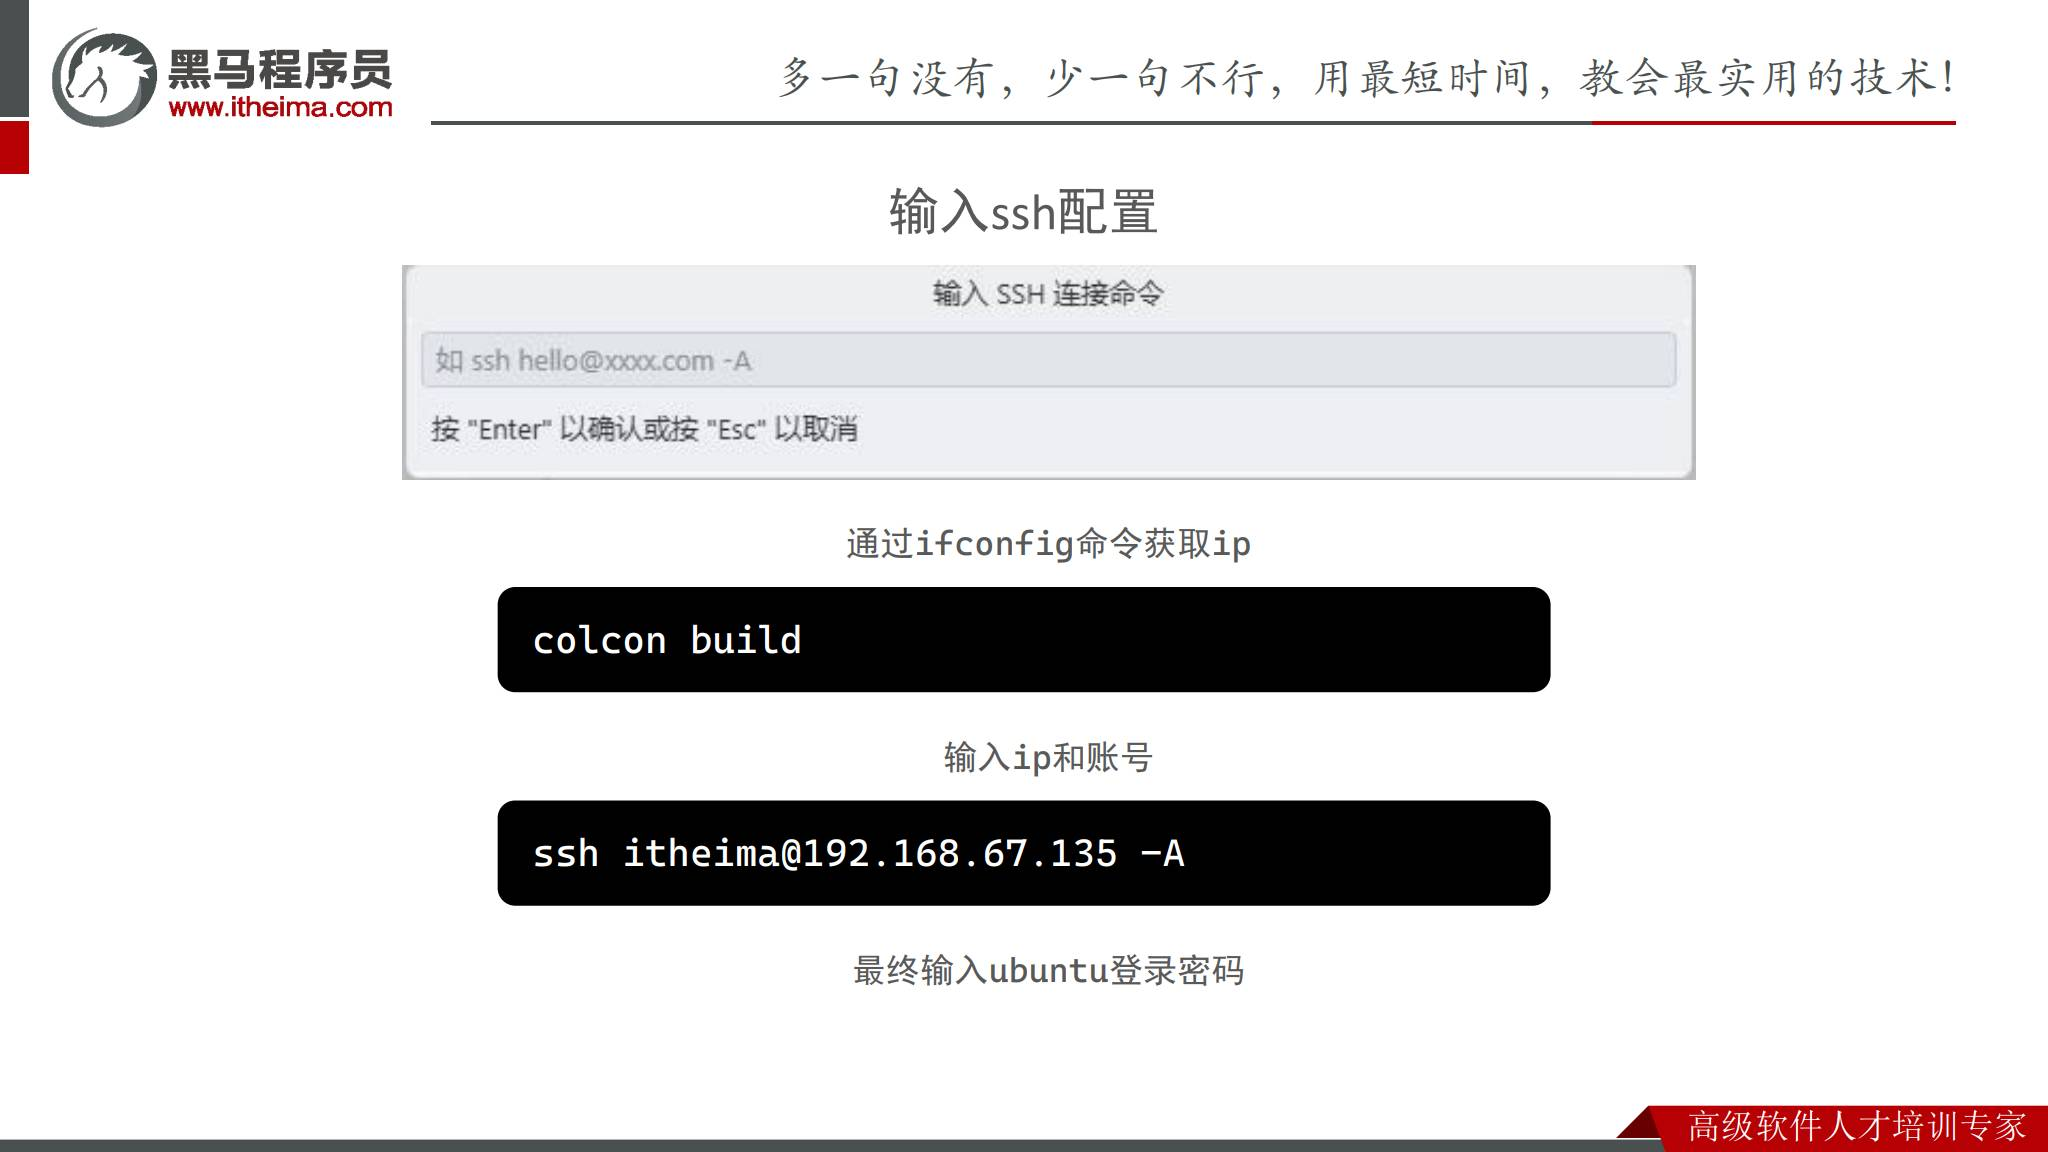

*原课件第16页：SSH配置、示例账户与地址。获取IP位置中的colcon build为笔误。*

课件文字写“通过`ifconfig`命令获取IP”，但其下方代码块误写`colcon build`。**工程补充纠正：`colcon build`用于构建，不查询IP。**Ubuntu中可以使用：

```bash
ip -brief address
```

选择虚拟机可访问的网络接口地址，不使用回环地址`127.0.0.1`。`ifconfig`在部分环境中未预装，查询IP并不必须先安装它。

课件SSH示例为`ssh itheima@192.168.67.135 -A`，用户名和IP必须换成自己的实际值。在Windows终端先尝试基本连接，形式为`ssh 用户名@虚拟机IP`，确认第02篇的SSH服务与网络连通后，再配置IDE。

**工程补充：**`-A`表示SSH代理转发，不是普通远程编辑必需参数。本阶段无代理转发需求时可省略。

远程连接后打开的是Ubuntu上的`~/dev_ws`。编辑器可以在Windows显示，文件、Python环境、构建工具与ROS节点却应在Ubuntu远程环境中运行。看到编辑器窗口不代表当前终端已经切到远程系统，可用`pwd`等确认目录与会话。

IDE是辅助工具，不替代`colcon build`与`source`。远程终端是否自动加载ROS环境也要实际检查；无需把课件界面位置当成所有软件版本的固定布局。


## 12. 常见问题与最小实践清单

| 现象 | 优先检查 | 解决方向 |
|---|---|---|
| `ros2`或`colcon`命令不存在 | 第02篇工具是否安装，ROS环境是否加载 | 先恢复基础开发环境 |
| 创建包提示目录已存在 | 同名包是否已生成 | 使用现有包，不重复执行创建命令 |
| 构建没有发现自己的包 | 当前目录与源码位置、package.xml、忽略标记 | 回到工作空间根目录，检查包结构 |
| 提示`Package 'my_package' not found` | 构建是否成功，是否source正确工作空间 | 检查install与包发现路径 |
| 提示找不到可执行程序 | console_scripts、setup.cfg、是否重新构建 | 检查入口注册和脚本安装位置 |
| `ModuleNotFoundError` | 模块路径、内层目录、Python依赖与环境 | 根据缺失模块具体排查 |
| 入口函数不存在 | `:main`是否与源码函数一致 | 修正函数名后重新构建 |
| 修改源码后仍执行旧逻辑 | 安装结果、当前包前缀、工作空间加载顺序 | 构建并确认正在运行哪个安装结果 |
| 程序一启动就结束 | 是否创建实际节点、是否进入spin | 检查main流程与具体异常 |
| SSH连接失败 | IP、用户名、服务与网络 | 先在Windows终端验证基本连接 |

**最小实践清单：**

- [ ] 已创建`~/dev_ws/src`并明确当前工作目录。
- [ ] 已创建`my_package`，理解外层与内层同名目录。
- [ ] `rclpy`依赖已声明，节点代码写在指定文件中。
- [ ] `console_scripts`入口与模块路径、函数名一致。
- [ ] 在`~/dev_ws`构建成功。
- [ ] 运行终端已加载Jazzy和项目环境。
- [ ] 可发现包与入口，节点启动并持续输出日志。
- [ ] 在另一终端能看到`/hello_node`。

清单用于读者实际操作记录，本篇未将其勾选为已经完成。

不要把“编辑器没有报红”“构建没有报错”和“节点功能运行正确”视为同一件事。它们验证的层次不同，完整开发过程需要逐层确认。


## 13. 复习题、流程回顾与下一篇

1. **工作空间和功能包是什么关系？**工作空间组织一组功能包，功能包提供可分发的代码、资源、依赖与构建规则。
2. **源码应该改在src还是install？**日常修改源码在src中的包目录，再通过构建更新安装结果。
3. **为什么Python包也要colcon build？**需要生成安装结果、资源索引和可执行入口，供ROS环境查找。
4. **`my_package.my_node:main`是什么意思？**在Python模块`my_package.my_node`中调用`main`函数。
5. **`ros2 run`第二个参数是什么？**已安装的可执行入口名，不必等于ROS图中的节点名。
6. **本例为什么显示/hello_node而不是/my_node？**Node构造函数指定运行时名称为`hello_node`，入口名则为`my_node`。
7. **source做了什么？**把相应安装环境的路径等设置加载到当前Shell，帮助工具发现包与程序。
8. **`colcon build`能否查询虚拟机IP？**不能；可用`ip -brief address`查看网络接口地址。

把完整链路记为：

```text
~/dev_ws/src/my_package             ROS功能包根目录
    └─ my_package/my_node.py        实际Python逻辑
        ↓ setup.py注册入口
colcon build                       构建安装
        ↓ source install/setup.bash
ros2 run my_package my_node         通过包与可执行名启动
        ↓ rclpy创建运行时节点
/hello_node                        ROS图中可观察的节点
```

第04篇对应《ROS通讯_Topic.pdf》，在节点工程的基础上继续学习话题、消息、发布者和订阅者，让多个模块交换业务数据。

可查阅官方教程入口：[ROS2 Jazzy创建功能包](https://docs.ros.org/en/jazzy/Tutorials/Beginner-Client-Libraries/Creating-Your-First-ROS2-Package.html)、[Python发布者与订阅者](https://docs.ros.org/en/jazzy/Tutorials/Beginner-Client-Libraries/Writing-A-Simple-Py-Publisher-And-Subscriber.html)。链接用于后续查阅，本篇没有将它们或未读附件内容当作已运行验证结果。
